# Kepler Exoplanet Detection — Exploratory Data Analysis

## Project Overview

This project explores NASA Kepler light-curve observations to investigate how planetary transits can be identified from stellar brightness variations.

The long-term objective is to develop a machine learning pipeline capable of distinguishing potential exoplanet transit signals from false positives.

### Objectives
- Retrieve and explore Kepler light-curve observations.
- Understand the characteristics of planetary transit signals.
- Apply preprocessing techniques, including normalization and phase folding.
- Investigate methods for extracting transit-related features.
- Prepare data for subsequent machine learning experiments.

### Data Sources
- **NASA Kepler Mission:** Stellar brightness measurements collected by the Kepler space telescope.
- **MAST Archive:** Public repository providing access to Kepler observations.
- **Lightkurve:** Python library for retrieving and analyzing astronomical light curves.

### Initial Target
Kepler-8 (KIC 6922244), a known exoplanet-hosting star, is used as an initial example to understand transit signatures.

**Scope:** This notebook focuses on data exploration and preprocessing. Model development and evaluation will be addressed in later stages.

## 1. Data Retrieval and Initial Visualization

### 1.1 Retrieving Kepler Light-Curve Data

Kepler light curves record changes in stellar brightness over time. Periodic decreases in brightness may indicate a planet passing in front of its host star.

In this section, the `lightkurve` library is used to:

1. Search the MAST archive for observations of Kepler-8.
2. Download a long-cadence light-curve segment.
3. Remove missing flux measurements.
4. Visualize stellar brightness as a function of time.

The initial analysis uses a single observation segment to examine the raw transit signature before applying further preprocessing.

Matplotlib is building the font cache; this may take a moment.
/Users/athieyun/.virtualenvs/kepler-exoplanet-detection-py3.12.15/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 18 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr006922244      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr006922244      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr006922244      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr006922244      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr006922244      0.0
  5 Kepler Quarter 05 2010 Kepler    1800 kplr006922244      0.0
  6 Kepler Quarter 06 2010 Kepler    1800 kplr006922244      0.0
  7 Kepler Quarter 07 2010 Kepler    1800 kplr006922244      0.0
  8 Kepler Quarter 08 2011 Kepler    1800 kplr006922244      0.0
  9 Kepler Quarter 09 2011 Kepler    1800 kplr006922244      0.0
 10 Kepler Quarter 10 2011 Kepler    1800 kplr006922244      0.0
 11 Kepler Quarter 11 2012 Kepler    1800 kplr0

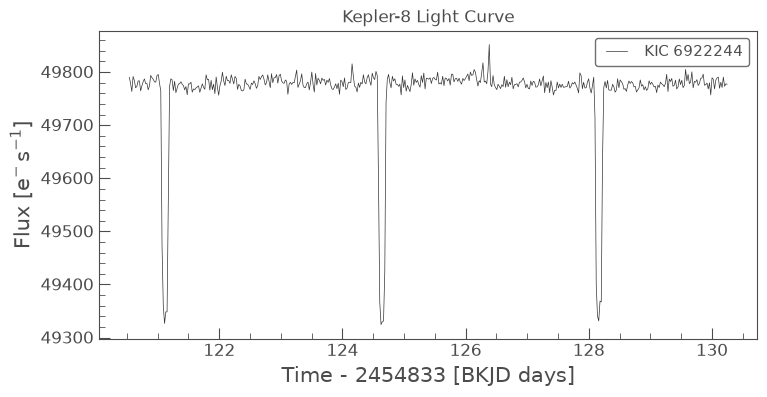

In [1]:
import lightkurve as lk
import matplotlib.pyplot as plt

# Search for Kepler-8 light curves
search_result = lk.search_lightcurve(
    "Kepler-8",
    mission="Kepler",
    author="Kepler",
    cadence="long"
)

print(search_result)

# Download one observation segment
lc = search_result[0].download()

# Remove invalid measurements
lc = lc.remove_nans()

# Plot stellar brightness over time
lc.plot()
plt.title("Kepler-8 Light Curve")
plt.show()

### 1.2 Initial Observations

The Kepler-8 light curve exhibits three prominent decreases in stellar brightness.

**Preliminary observations:**

- **Baseline flux:** Approximately 49,780 electrons/s.
- **Transit minimum:** Approximately 49,330 electrons/s.
- **Transit depth:** Approximately 0.90% relative brightness reduction.
- **Transit periodicity:** The three dips appear approximately 3.5 days apart.
- **Signal variability:** Small fluctuations are present outside the transit events.

The relatively regular spacing and similar depths of the observed dips are consistent with repeated planetary transits.

However, periodic brightness decreases alone are insufficient to confirm the presence of an exoplanet. Additional analysis is required to distinguish planetary transits from other astrophysical phenomena and instrumental effects.

**Next steps:** Normalize the light curve and apply phase folding to examine the repeated transit pattern more clearly.

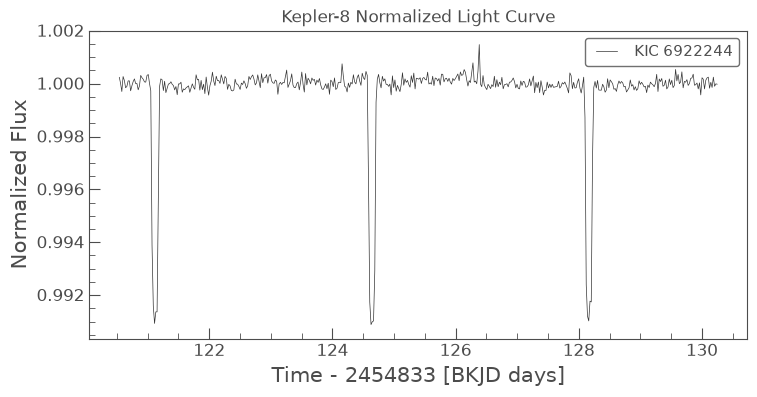

In [2]:
# Normalize the light curve
lc_normalized = lc.normalize()

# Visualize
ax = lc_normalized.plot()
ax.set_title("Kepler-8 Normalized Light Curve")
plt.show()

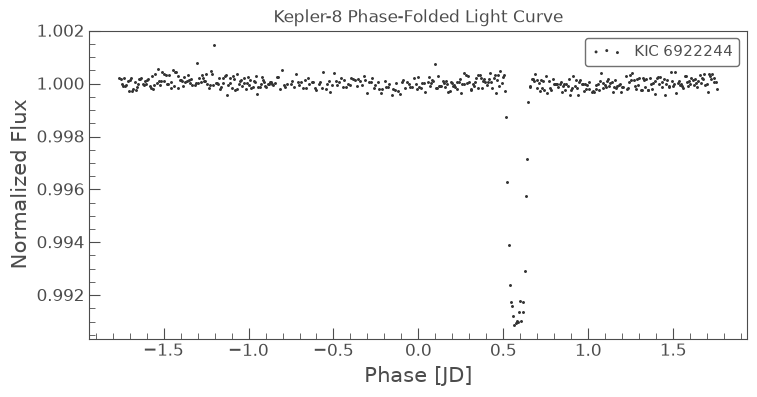

In [3]:
# Approximate orbital period of Kepler-8b
period = 3.5225

# Fold the normalized light curve
lc_folded = lc_normalized.fold(period=period)

ax = lc_folded.scatter(s=5)
ax.set_title("Kepler-8 Phase-Folded Light Curve")
plt.show()